In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU count:", torch.cuda.device_count())
else:
    print("⚠️ GPU NOT AVAILABLE")

PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: NVIDIA A100-SXM4-40GB
GPU count: 1


In [2]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
from pathlib import Path

drive_dataset = Path("/content/drive/MyDrive/final_dataset")

print("Dataset exists:", drive_dataset.exists())

if drive_dataset.exists():
    print("\nContents:")
    for item in drive_dataset.iterdir():
        print(item.name)

Dataset exists: True

Contents:
train
val
test
data.yaml
data_colab.yaml


In [4]:
for split in ["train", "val", "test"]:

    image_dir = drive_dataset / split / "images"
    label_dir = drive_dataset / split / "labels"

    images = list(image_dir.glob("*"))
    labels = list(label_dir.glob("*.txt"))

    print(
        f"{split.upper():5} → "
        f"Images: {len(images):,} | "
        f"Labels: {len(labels):,}"
    )

TRAIN → Images: 15,000 | Labels: 15,000
VAL   → Images: 2,000 | Labels: 2,000
TEST  → Images: 2,000 | Labels: 2,000


In [5]:
!pip install -q -U ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 72.3 MB/s eta 0:00:00


In [6]:
import ultralytics

print("Ultralytics version:", ultralytics.__version__)

Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics version: 8.4.117


In [7]:
from ultralytics import YOLO

print("YOLO imported successfully!")

YOLO imported successfully!


In [8]:
!ls -lah /content/drive/MyDrive/final_dataset/

total 13K
-rw------- 1 root root  189 Aug 10 09:13 data_colab.yaml
-rw------- 1 root root  174 Aug  8 10:47 data.yaml
drwx------ 4 root root 4.0K Aug  8 10:45 test
drwx------ 4 root root 4.0K Aug  8 10:29 train
drwx------ 4 root root 4.0K Aug  8 10:43 val


In [9]:
DATASET = "/content/drive/MyDrive/final_dataset"

!find "$DATASET" -maxdepth 2 -type d

/content/drive/MyDrive/final_dataset
/content/drive/MyDrive/final_dataset/train
/content/drive/MyDrive/final_dataset/train/images
/content/drive/MyDrive/final_dataset/train/labels
/content/drive/MyDrive/final_dataset/val
/content/drive/MyDrive/final_dataset/val/images
/content/drive/MyDrive/final_dataset/val/labels
/content/drive/MyDrive/final_dataset/test
/content/drive/MyDrive/final_dataset/test/images
/content/drive/MyDrive/final_dataset/test/labels


In [10]:
from pathlib import Path

dataset_path = Path(DATASET)

for split in ["train", "val", "test"]:
    image_dir = dataset_path / split / "images"

    images = []
    for ext in ["*.jpg", "*.jpeg", "*.png", "*.bmp", "*.webp"]:
        images.extend(image_dir.glob(ext))

    print(f"{split.upper():5} images:", len(images))

TRAIN images: 15000
VAL   images: 2000
TEST  images: 2000


In [11]:
for split in ["train", "val", "test"]:
    label_dir = dataset_path / split / "labels"
    labels = list(label_dir.glob("*.txt"))

    print(f"{split.upper():5} labels:", len(labels))

TRAIN labels: 15000
VAL   labels: 2000
TEST  labels: 2000


In [12]:
!cat "$DATASET/data.yaml"

path: /content/final_dataset

train: train/images
val: val/images
test: test/images

nc: 6

names:
  0: car
  1: motorcycle
  2: bus
  3: truck
  4: autorickshaw
  5: bicycle

In [13]:
from ultralytics import YOLO

model = YOLO("yolo11s.pt")

In [14]:
from pathlib import Path

COLAB_YAML = Path("/content/drive/MyDrive/final_dataset/data_colab.yaml")

yaml_content = """path: /content/drive/MyDrive/final_dataset

train: train/images
val: val/images
test: test/images

nc: 6

names:
  0: car
  1: motorcycle
  2: bus
  3: truck
  4: autorickshaw
  5: bicycle
"""

COLAB_YAML.write_text(yaml_content)

print("Created:", COLAB_YAML)
print()
print(COLAB_YAML.read_text())

Created: /content/drive/MyDrive/final_dataset/data_colab.yaml

path: /content/drive/MyDrive/final_dataset

train: train/images
val: val/images
test: test/images

nc: 6

names:
  0: car
  1: motorcycle
  2: bus
  3: truck
  4: autorickshaw
  5: bicycle



In [15]:
from ultralytics import YOLO

model = YOLO("yolo11s.pt")

print("Model loaded successfully.")
print("Dataset YAML:", COLAB_YAML)

Model loaded successfully.
Dataset YAML: /content/drive/MyDrive/final_dataset/data_colab.yaml


In [16]:
results = model.val(
    data=str(COLAB_YAML),
    imgsz=640,
    batch=8,
    device=0
)

Ultralytics 8.4.117 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
YOLO11s summary (fused): 100 layers, 9,443,760 parameters, 0 gradients, 21.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.4±0.1 ms, read: 0.6±0.3 MB/s, size: 436.7 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips/
val: Scanning /content/drive/MyDrive/final_dataset/val/labels.cache... 2000 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2000/2000 524.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 250/250 2.0it/s 2:07
                   all       2000      14291     0.0324      0.197     0.0129    0.00512
                person       1342       4601    0.00887      0.186    0.00179   0.000504
               bicycle       1467       5351      0.139      0.348     0.0676     0.0263
                   car        568

In [17]:
from collections import Counter
from pathlib import Path

class_counts = Counter()

for split in ["train", "val", "test"]:
    label_dir = Path(DATASET) / split / "labels"

    for label_file in label_dir.glob("*.txt"):
        with open(label_file, "r") as f:
            for line in f:
                parts = line.strip().split()

                if not parts:
                    continue

                class_id = int(parts[0])
                class_counts[class_id] += 1

print("Class ID distribution:")
for class_id in sorted(class_counts):
    print(f"Class {class_id}: {class_counts[class_id]} instances")

print("\nUnique class IDs:", sorted(class_counts.keys()))

Class ID distribution:
Class 0: 44775 instances
Class 1: 50861 instances
Class 2: 9351 instances
Class 3: 13886 instances
Class 4: 15947 instances
Class 5: 1584 instances

Unique class IDs: [0, 1, 2, 3, 4, 5]


In [22]:
import yaml

with open(COLAB_YAML, "r") as f:
    data_config = yaml.safe_load(f)

print("Number of classes:", data_config["nc"])
print("Class names:")

for k, v in data_config["names"].items():
    print(k, "->", v)

Number of classes: 6
Class names:
0 -> car
1 -> motorcycle
2 -> bus
3 -> truck
4 -> autorickshaw
5 -> bicycle


In [23]:
!cp -r "/content/drive/MyDrive/final_dataset" "/content/"

In [24]:
from pathlib import Path

LOCAL_YAML = Path("/content/final_dataset/data_local.yaml")

yaml_content = """path: /content/final_dataset

train: train/images
val: val/images
test: test/images

nc: 6

names:
  0: car
  1: motorcycle
  2: bus
  3: truck
  4: autorickshaw
  5: bicycle
"""

LOCAL_YAML.write_text(yaml_content)

print("Local YAML created successfully:")
print(LOCAL_YAML)
print("\n--- YAML CONTENT ---")
print(LOCAL_YAML.read_text())

Local YAML created successfully:
/content/final_dataset/data_local.yaml

--- YAML CONTENT ---
path: /content/final_dataset

train: train/images
val: val/images
test: test/images

nc: 6

names:
  0: car
  1: motorcycle
  2: bus
  3: truck
  4: autorickshaw
  5: bicycle



In [25]:
from pathlib import Path

LOCAL_DATASET = Path("/content/final_dataset")

for split in ["train", "val", "test"]:
    img_dir = LOCAL_DATASET / split / "images"
    lbl_dir = LOCAL_DATASET / split / "labels"

    image_count = sum(
        1 for ext in ["*.jpg", "*.jpeg", "*.png", "*.bmp", "*.webp"]
        for _ in img_dir.glob(ext)
    )

    label_count = len(list(lbl_dir.glob("*.txt")))

    print(
        f"{split.upper():5} | "
        f"images: {image_count:5} | "
        f"labels: {label_count:5}"
    )

TRAIN | images: 15000 | labels: 15000
VAL   | images:  2000 | labels:  2000
TEST  | images:  2000 | labels:  2000


In [26]:
!nvidia-smi

Mon Aug 10 14:14:10 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   33C    P0             54W /  400W |    1202MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [27]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/YOLO11_Training")
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

print("Training results will be saved to:")
print(PROJECT_DIR)

Training results will be saved to:
/content/drive/MyDrive/YOLO11_Training


In [28]:
import os

RUN_DIR = PROJECT_DIR / "yolo11s_vehicle_detection"

if RUN_DIR.exists():
    print("⚠️ Existing training directory found:")
    print(RUN_DIR)
    print("\nContents:")
    for item in RUN_DIR.iterdir():
        print(" -", item.name)
else:
    print("No previous training run found.")
    print("Ready for a fresh training run.")

⚠️ Existing training directory found:
/content/drive/MyDrive/YOLO11_Training/yolo11s_vehicle_detection

Contents:
 - weights
 - args.yaml
 - labels.jpg
 - train_batch0.jpg
 - train_batch1.jpg
 - train_batch2.jpg
 - results.csv


In [29]:
from ultralytics import YOLO

model = YOLO("yolo11s.pt")

print("YOLO11s loaded successfully.")

YOLO11s loaded successfully.


In [30]:
results = model.train(
    data="/content/final_dataset/data_local.yaml",

    # Training duration
    epochs=50,

    # Image resolution
    imgsz=640,

    # Automatically select batch size
    batch=-1,

    # Use GPU
    device=0,

    # Start from pretrained YOLO11s
    pretrained=True,

    # Stop if validation does not improve
    patience=10,

    # Save results to Google Drive
    project="/content/drive/MyDrive/YOLO11_Training",
    name="yolo11s_vehicle_detection",

    # Save checkpoints
    save=True,
    save_period=10,

    # Generate plots
    plots=True,

    # Reproducibility
    seed=42,

    # Show training progress
    verbose=True
)

Ultralytics 8.4.117 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/final_dataset/data_local.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11s_v

In [31]:
from pathlib import Path

BEST_MODEL = Path(
    "/content/drive/MyDrive/YOLO11_Training/"
    "yolo11s_vehicle_detection-3/weights/best.pt"
)

print("Best model exists:", BEST_MODEL.exists())
print("Model path:", BEST_MODEL)

Best model exists: True
Model path: /content/drive/MyDrive/YOLO11_Training/yolo11s_vehicle_detection-3/weights/best.pt


In [32]:
from ultralytics import YOLO

best_model = YOLO(str(BEST_MODEL))

print("best.pt loaded successfully.")

best.pt loaded successfully.


In [34]:
test_results = best_model.val(
    data="/content/final_dataset/data_local.yaml",
    split="test",
    imgsz=640,
    batch=8, # Changed from -1 to 8
    device=0,
    plots=True
)

Ultralytics 8.4.117 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3277.0±267.6 MB/s, size: 470.0 KB)
val: Scanning /content/final_dataset/test/labels.cache... 2000 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2000/2000 699.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 250/250 20.3it/s 12.3s
                   all       2000      14759      0.835      0.583      0.665      0.467
                   car       1337       4840      0.873      0.594      0.683      0.484
            motorcycle       1445       5426      0.824      0.615      0.681      0.416
                   bus        595       1032      0.899      0.638      0.736      0.564
                 truck        833       1470      0.819      0.607      0.689       0.52
          autorickshaw        782       1810      0.866      0.645      0.726      0.533
            

In [35]:
from pathlib import Path

print("Test results saved.")
print("Check the generated confusion matrix in the test results directory.")

Test results saved.
Check the generated confusion matrix in the test results directory.


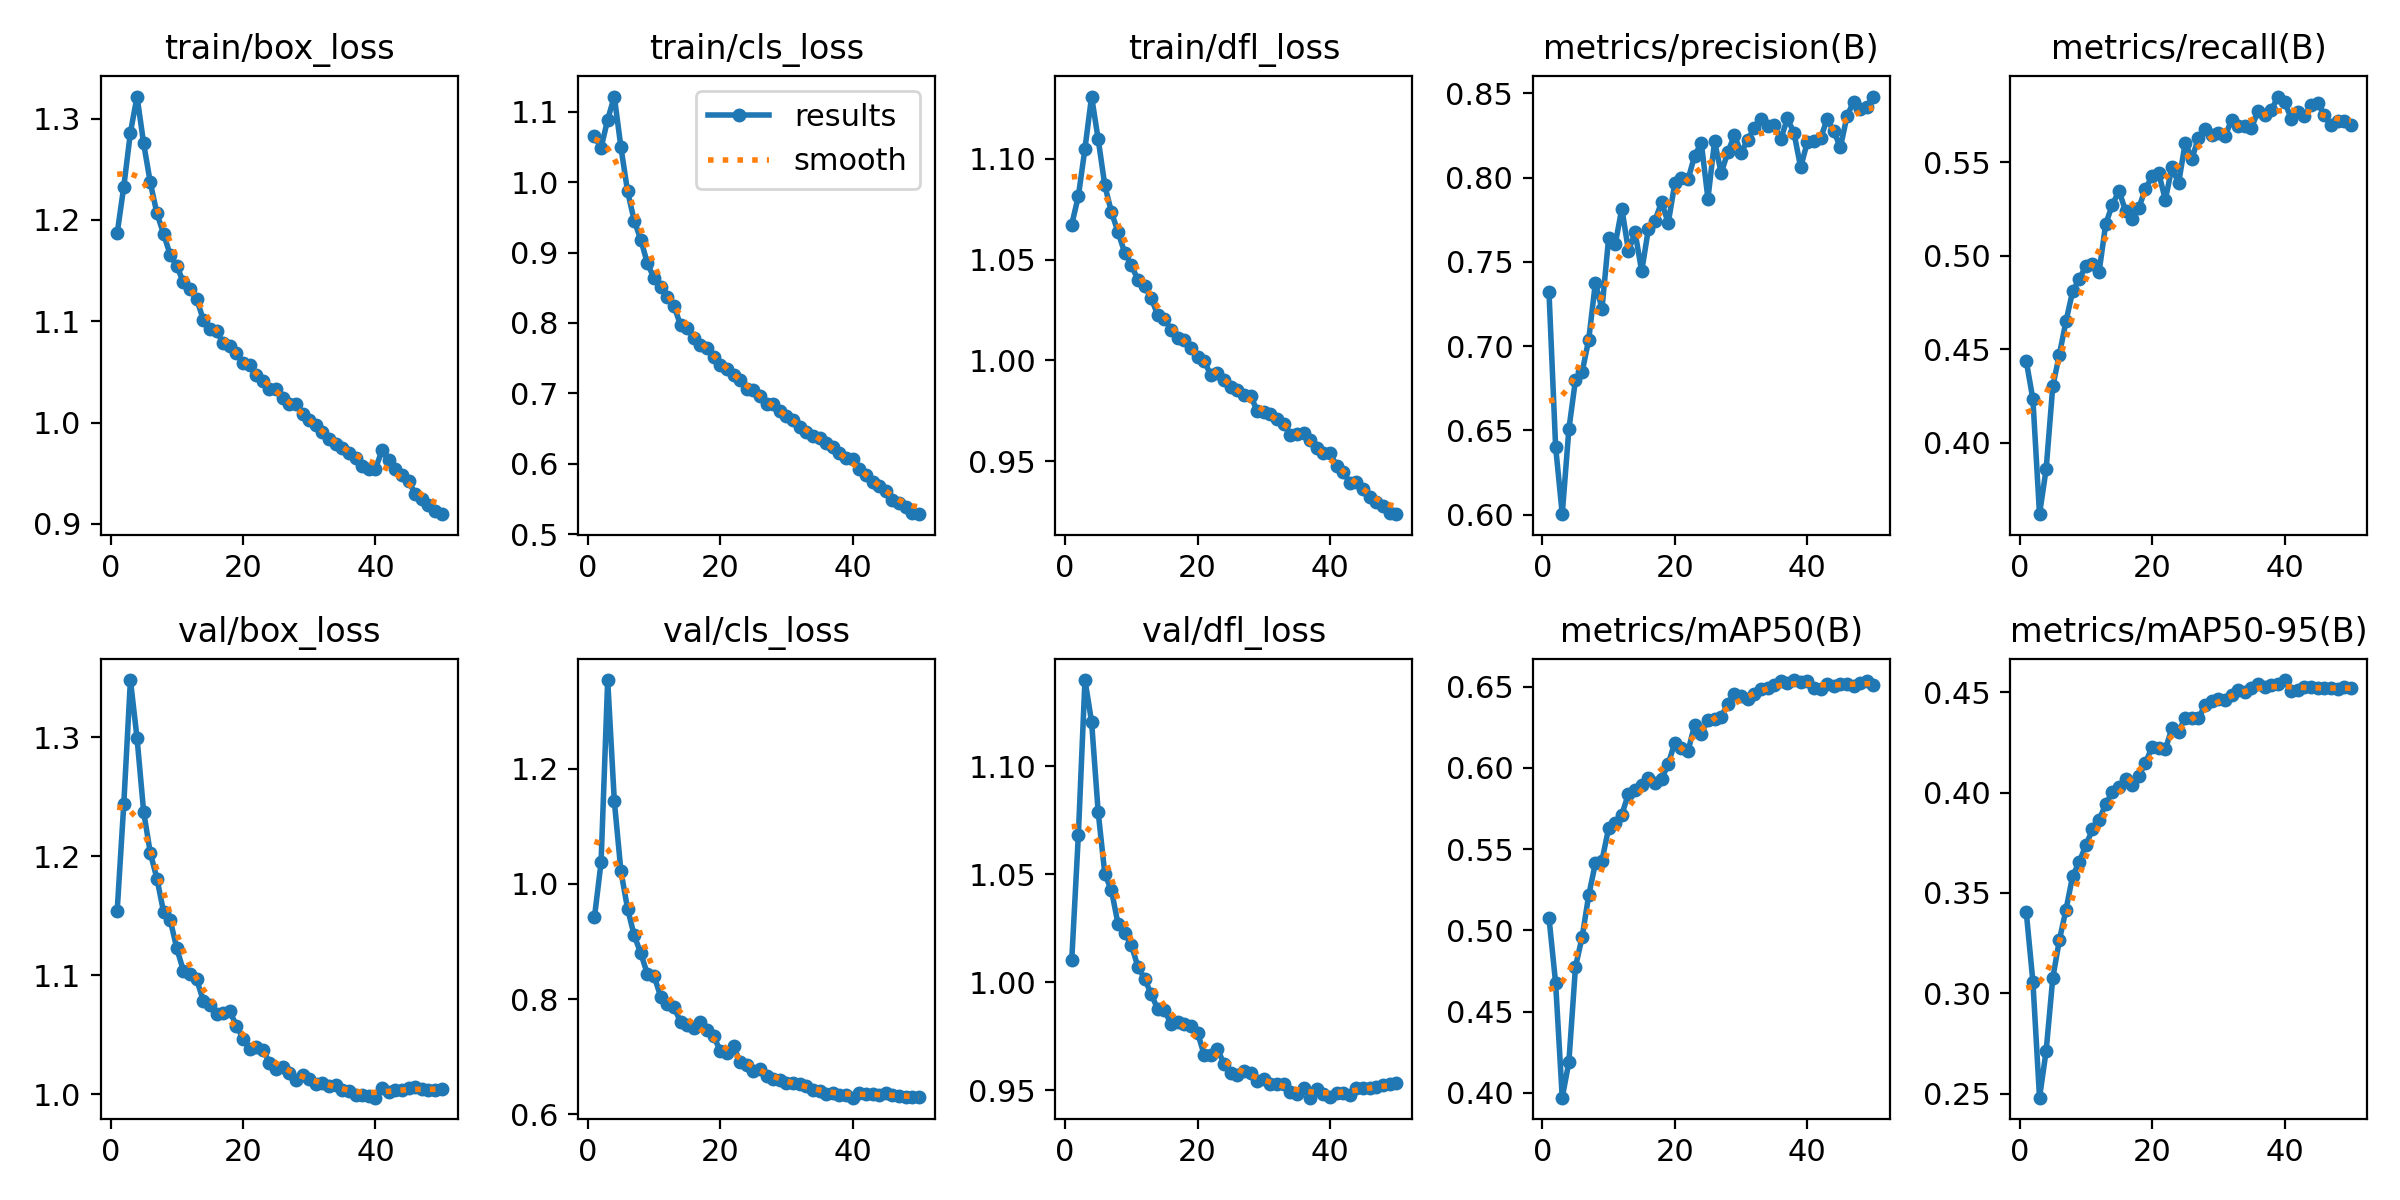

In [36]:
from IPython.display import Image, display
display(Image("/content/drive/MyDrive/YOLO11_Training/yolo11s_vehicle_detection-3/results.png"))

In [37]:
pred_results = best_model.predict(
    source="/content/final_dataset/test/images",
    imgsz=640,
    conf=0.25,
    device=0,
    save=True,
    project="/content/drive/MyDrive/YOLO11_Training",
    name="test_predictions"
)


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict/ for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

image 1/2000 /content/final_dataset/test/images/15-07-18-upload_0001999.jpg: 384x640 6 cars, 8 motorcycles, 2 trucks, 3 autorickshaws, 9.5ms
image 2/2000 /content/final_dataset/test/images/15-07-18-upload_0004513.jpg: 384x640 6 cars, 6 motorcycles, 2 trucks, 1 autorickshaw, 9.7ms
image 3/2000 /content/final_dataset/test/images/15-07-18-upload_0004554.jpg: 384x640 11 cars, 5 motorcycles, 9.7ms
image 4/2000 /content/final_dataset/test/images/15-07-18-uploa

Files in test results folder:
val_batch1_labels.jpg
val_batch0_labels.jpg
BoxF1_curve.png
val_batch0_pred.jpg
val_batch2_labels.jpg
val_batch2_pred.jpg
BoxR_curve.png
val_batch1_pred.jpg
BoxPR_curve.png
confusion_matrix.png
BoxP_curve.png
confusion_matrix_normalized.png

Confusion Matrix:


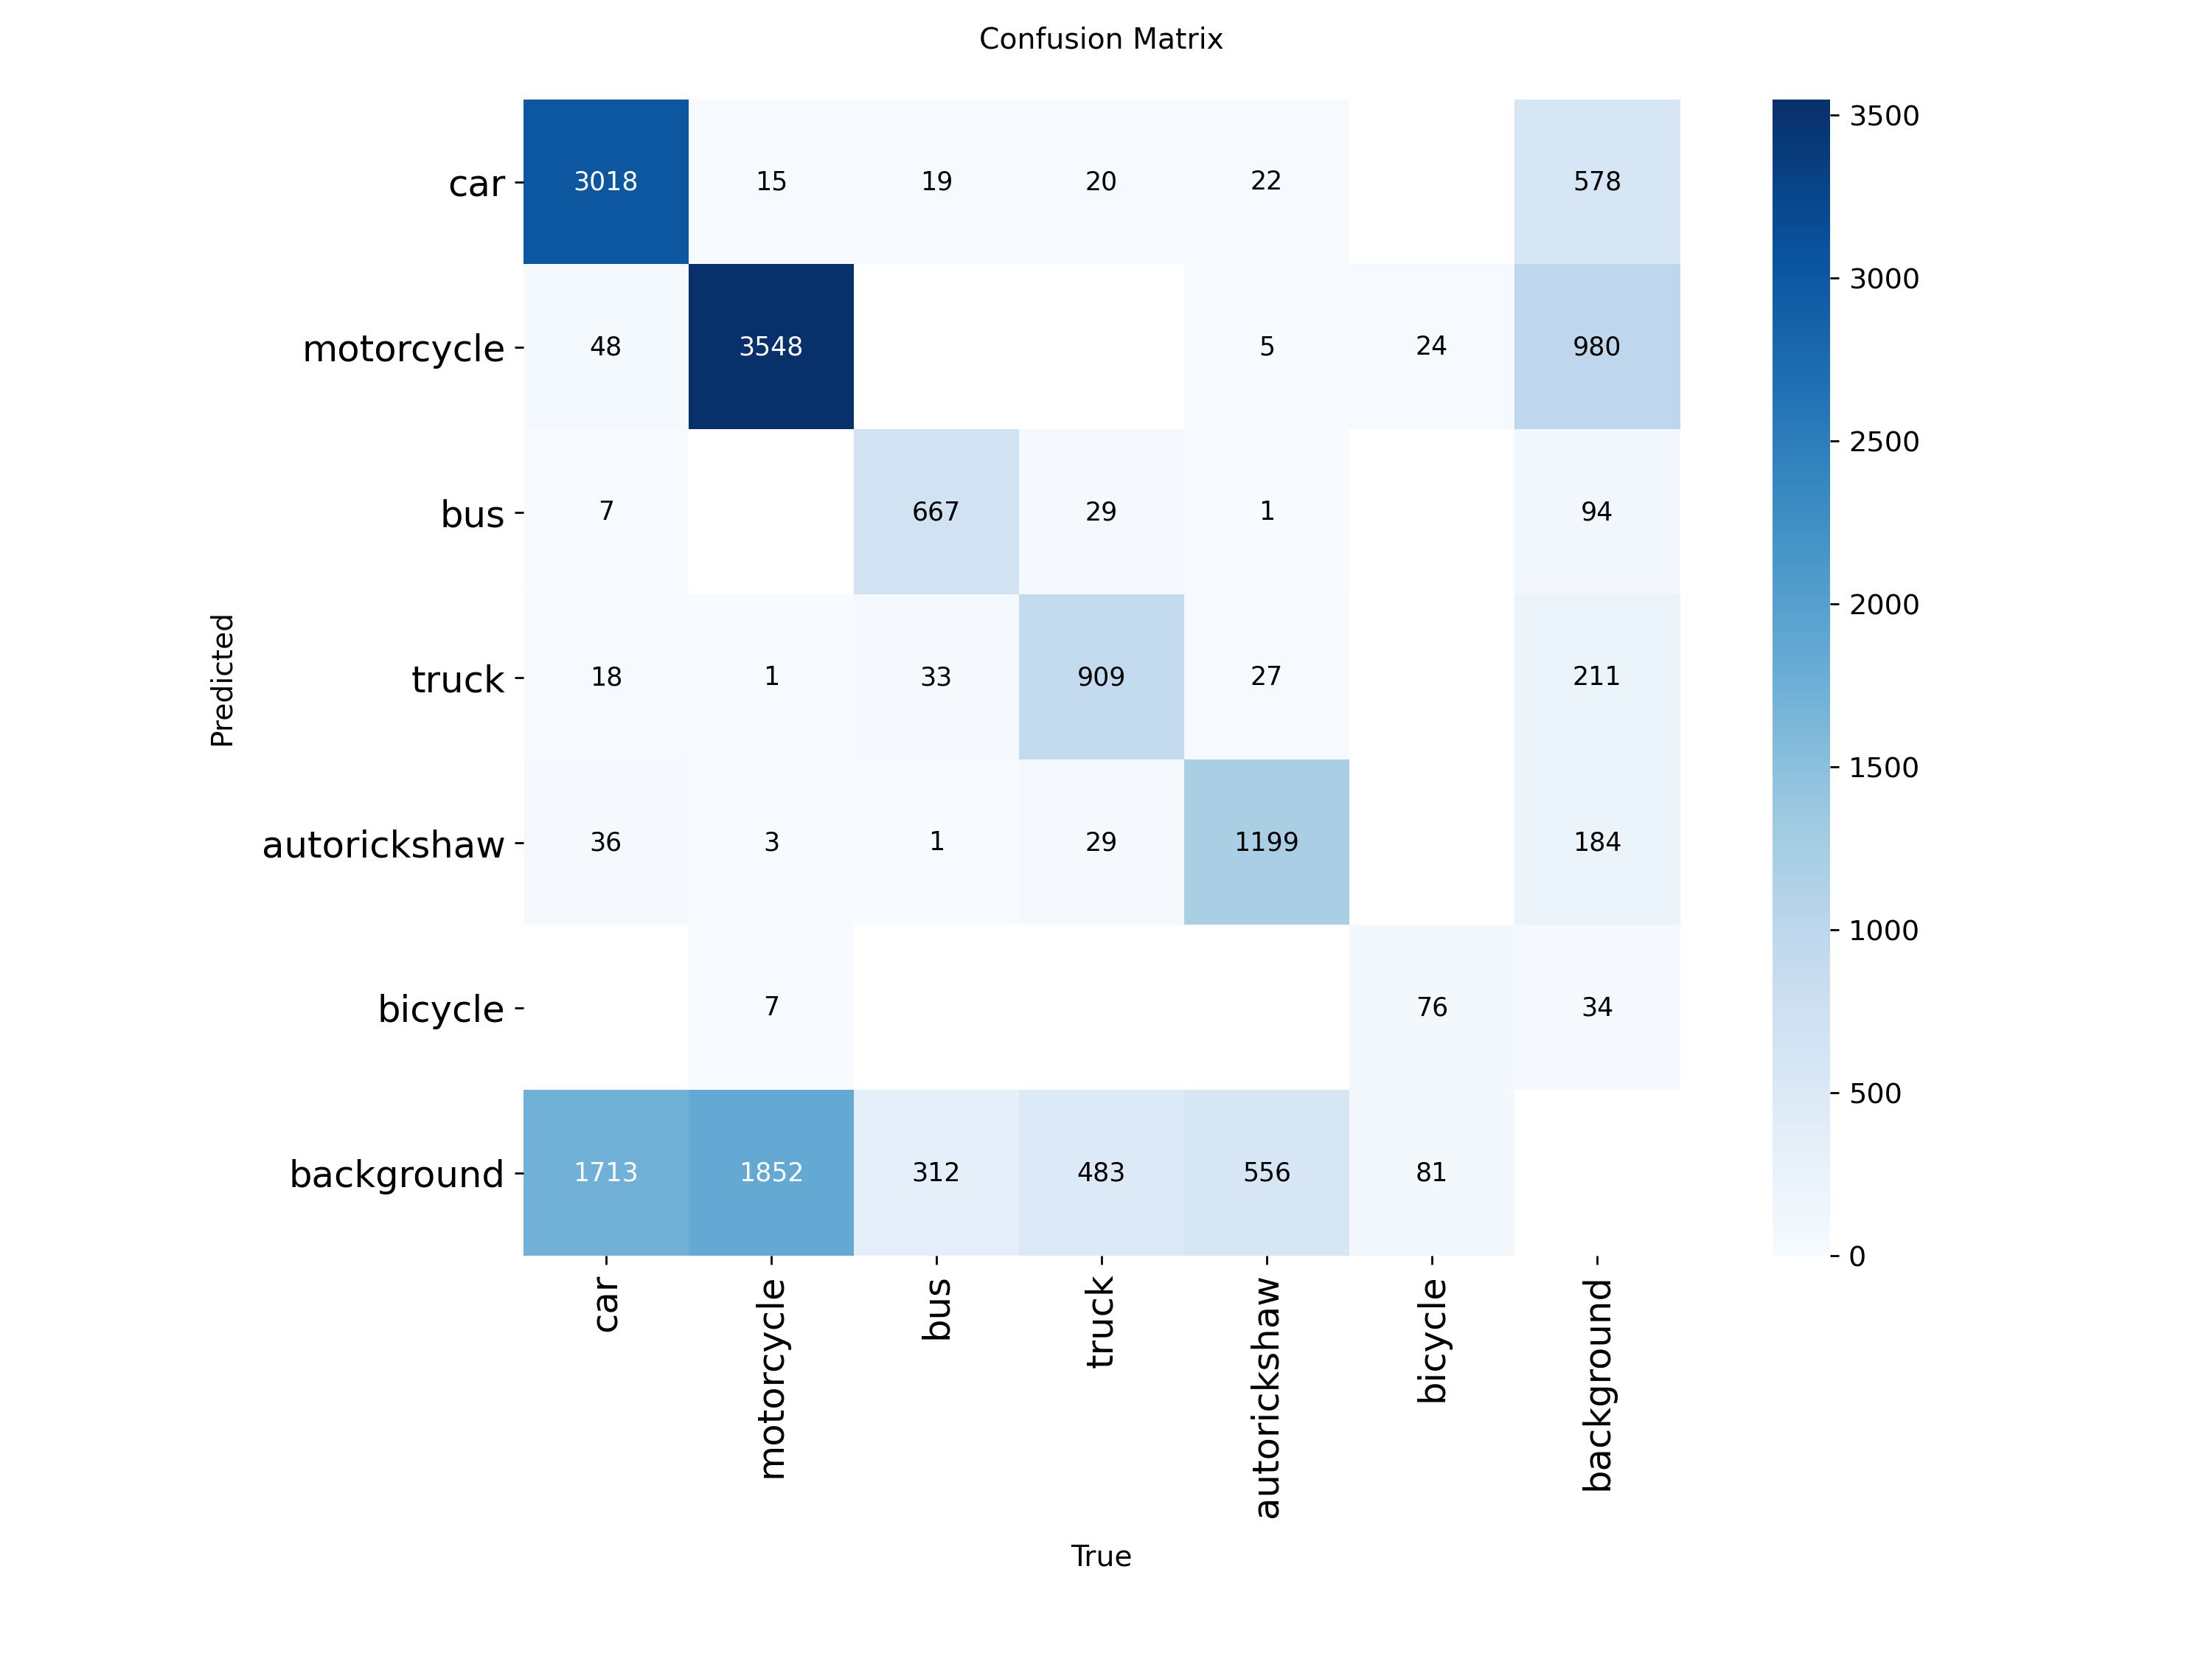

In [39]:
from IPython.display import Image, display
from pathlib import Path

CONF_DIR = Path("/content/runs/detect/val-3")

print("Files in test results folder:")
for f in CONF_DIR.iterdir():
    print(f.name)

print("\nConfusion Matrix:")
display(Image(filename=str(CONF_DIR / "confusion_matrix.png")))

In [40]:
pred_results = best_model.predict(
    source="/content/final_dataset/test/images",
    imgsz=640,
    conf=0.25,
    device=0,
    save=True,
    project="/content/drive/MyDrive/YOLO11_Training",
    name="test_predictions",
    exist_ok=True
)

print("Test predictions generated successfully.")


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict/ for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

image 1/2000 /content/final_dataset/test/images/15-07-18-upload_0001999.jpg: 384x640 6 cars, 8 motorcycles, 2 trucks, 3 autorickshaws, 11.4ms
image 2/2000 /content/final_dataset/test/images/15-07-18-upload_0004513.jpg: 384x640 6 cars, 6 motorcycles, 2 trucks, 1 autorickshaw, 10.4ms
image 3/2000 /content/final_dataset/test/images/15-07-18-upload_0004554.jpg: 384x640 11 cars, 5 motorcycles, 10.1ms
image 4/2000 /content/final_dataset/test/images/15-07-18-up

Total prediction images: 2000

Displaying first 6:
15-07-18-upload_0001999.jpg


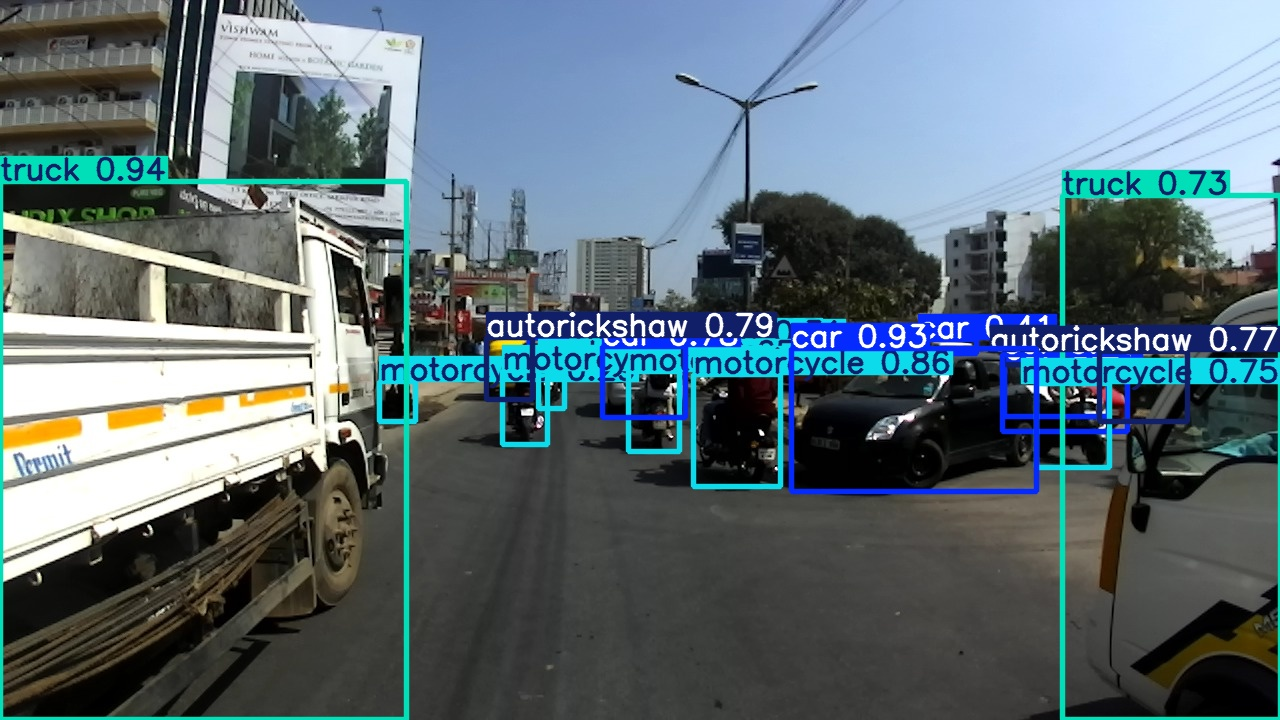

15-07-18-upload_0004513.jpg


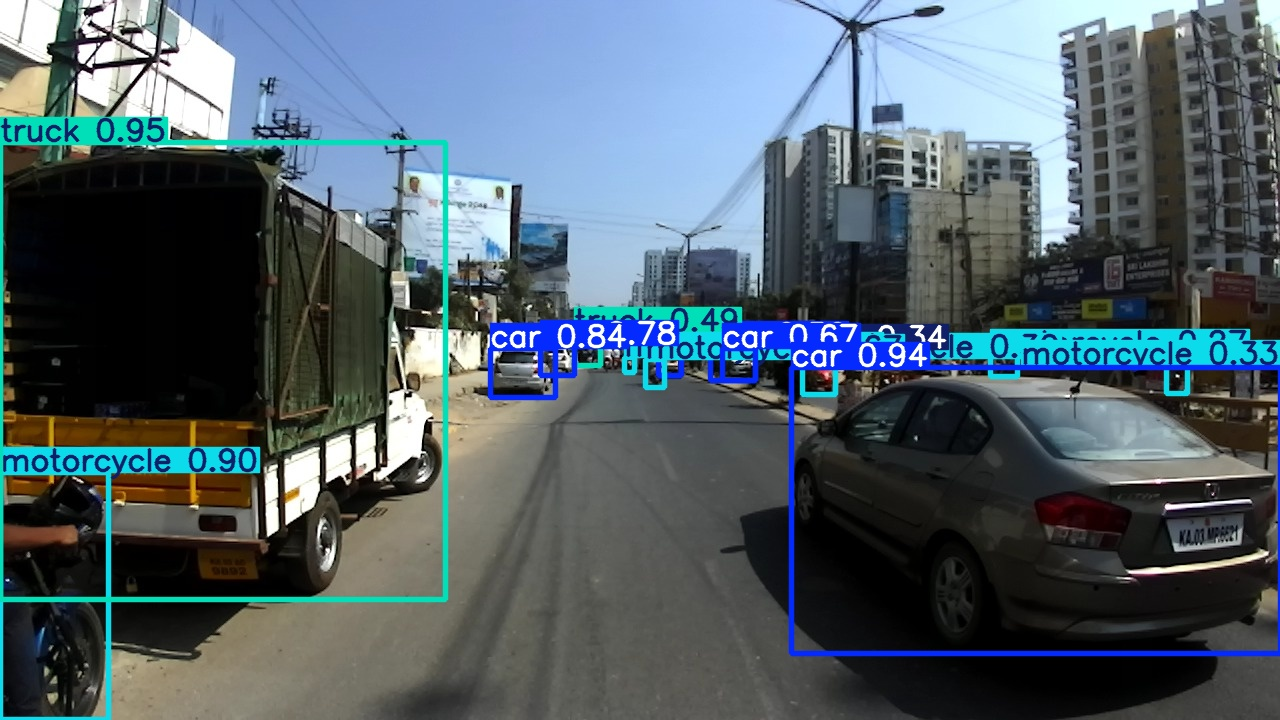

15-07-18-upload_0004554.jpg


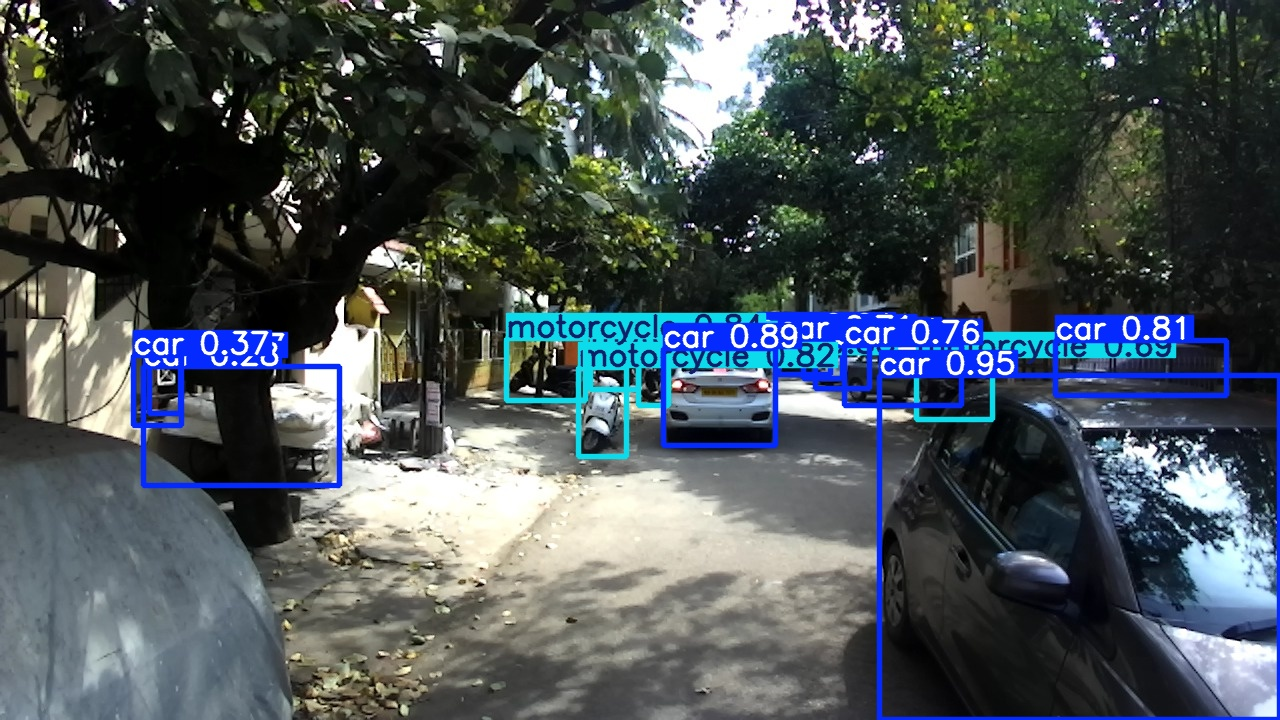

15-07-18-upload_0004586.jpg


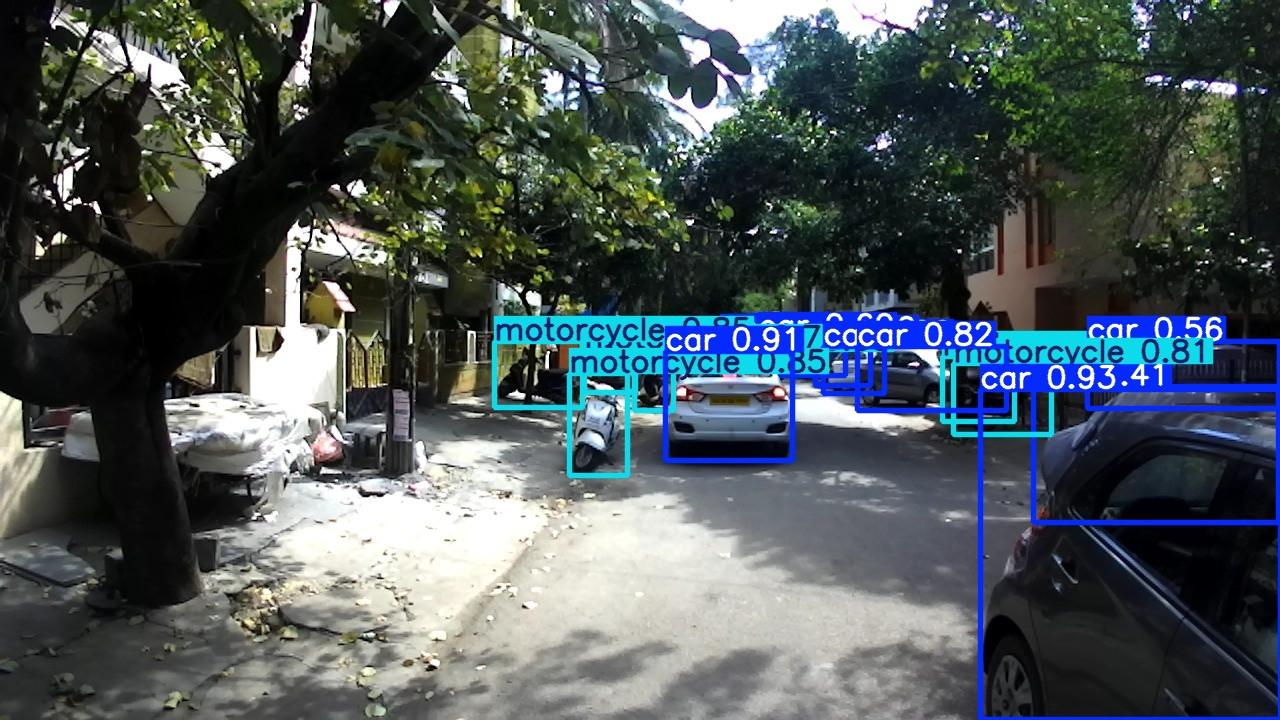

15-07-18-upload_0007177.jpg


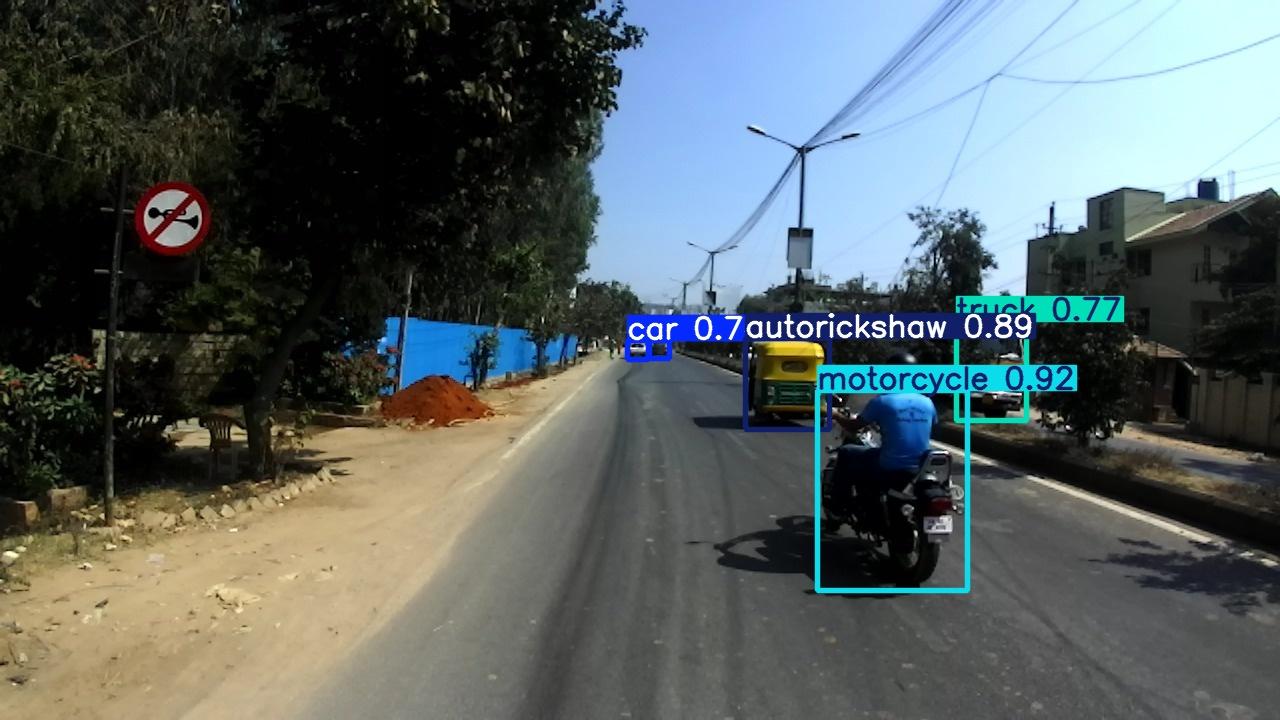

15-07-18-upload_0007321.jpg


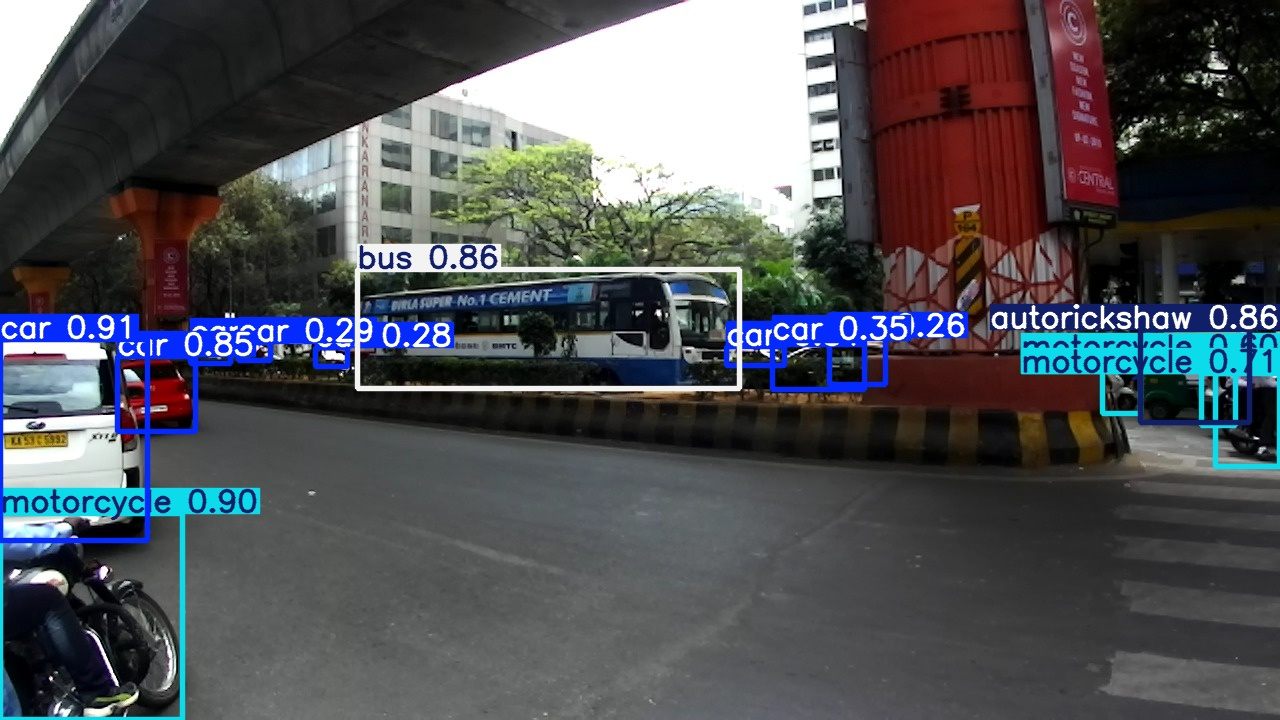

In [41]:
from pathlib import Path
from IPython.display import Image, display

PRED_DIR = Path(
    "/content/drive/MyDrive/YOLO11_Training/test_predictions"
)

images = list(PRED_DIR.glob("*.jpg")) + list(PRED_DIR.glob("*.png"))

print("Total prediction images:", len(images))
print("\nDisplaying first 6:")

for img in images[:6]:
    print(img.name)
    display(Image(filename=str(img), width=800))

In [42]:
from google.colab import files

best_pt = "/content/drive/MyDrive/YOLO11_Training/yolo11s_vehicle_detection-3/weights/best.pt"

files.download(best_pt)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [43]:
import os
import shutil
from google.colab import files

project_dir = "/content/drive/MyDrive/YOLO11_Training/yolo11s_vehicle_detection-3"

# Create a package
package_dir = "/content/yolo11_final_package"
os.makedirs(package_dir, exist_ok=True)

# Best trained model
shutil.copy(
    f"{project_dir}/weights/best.pt",
    f"{package_dir}/best.pt"
)

# Training results/metrics
if os.path.exists(f"{project_dir}/results.png"):
    shutil.copy(
        f"{project_dir}/results.png",
        f"{package_dir}/results.png"
    )

# Create ZIP
shutil.make_archive(
    "/content/yolo11_final_package",
    "zip",
    package_dir
)

files.download("/content/yolo11_final_package.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>